In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

# Set base paths
DATA_DIR = Path("../data")
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test" / "test"

# Verify directory existence
assert DATA_DIR.exists(), "Data directory not found. Check relative paths."
assert TRAIN_DIR.exists(), "Train directory not found."

Total rows in train.csv: 32003
Total .tif files found on disk: 32003


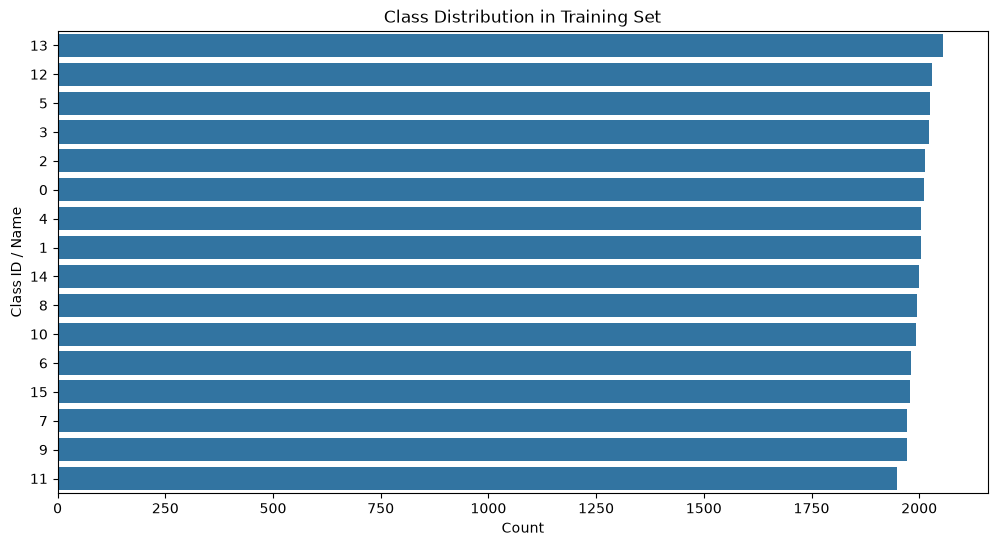

In [5]:
train_df = pd.read_csv(DATA_DIR / "train.csv")
print(f"Total rows in train.csv: {len(train_df)}")

# Assuming train.csv has 'image_path' (or 'filename') and 'label' columns. 
# Adjust column names 'filename' and 'label' based on your actual CSV header.
image_paths = list(TRAIN_DIR.rglob("*.tif"))
disk_files = [p.name for p in image_paths]

print(f"Total .tif files found on disk: {len(disk_files)}")

# Check for class imbalance
plt.figure(figsize=(12, 6))
sns.countplot(data=train_df, y='label', order=train_df['label'].value_counts().index)
plt.title("Class Distribution in Training Set")
plt.xlabel("Count")
plt.ylabel("Class ID / Name")
plt.show()

100%|██████████| 2000/2000 [00:02<00:00, 692.75it/s]



Image Modes (Channels):
mode
L    2000
Name: count, dtype: int64


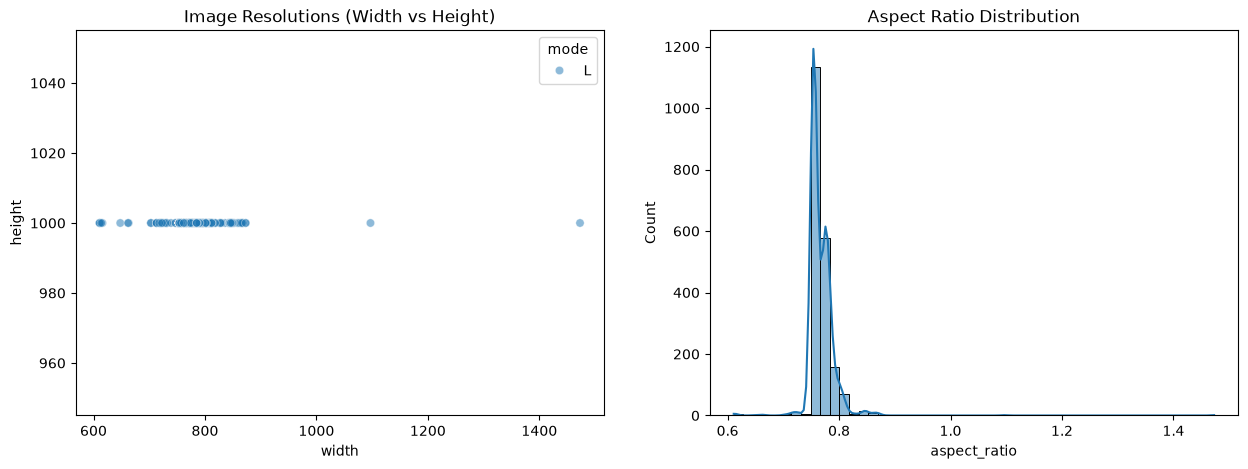

In [6]:
def get_image_metadata(img_path):
    try:
        with Image.open(img_path) as img:
            return {
                "filename": img_path.name,
                "width": img.width,
                "height": img.height,
                "mode": img.mode, # 'L' (grayscale), 'RGB', 'RGBA', 'CMYK'
                "aspect_ratio": img.width / img.height
            }
    except Exception as e:
        return {"filename": img_path.name, "error": str(e)}

# Sample 2000 images to save time, or run on full dataset if desired
sample_paths = np.random.choice(image_paths, min(len(image_paths), 2000), replace=False)

with ThreadPoolExecutor(max_workers=8) as executor:
    metadata = list(tqdm(executor.map(get_image_metadata, sample_paths), total=len(sample_paths)))

meta_df = pd.DataFrame(metadata)

if 'error' in meta_df.columns:
    errors = meta_df[meta_df['error'].notnull()]
    print(f"Found {len(errors)} corrupted images.")

# Display channel distributions
print("\nImage Modes (Channels):")
print(meta_df['mode'].value_counts())

# Plot aspect ratio and resolution distribution
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=meta_df, x='width', y='height', hue='mode', alpha=0.5, ax=ax[0])
ax[0].set_title("Image Resolutions (Width vs Height)")

sns.histplot(meta_df['aspect_ratio'], bins=50, kde=True, ax=ax[1])
ax[1].set_title("Aspect Ratio Distribution")
plt.show()